# Conjugate gradient against weighted GS: what an explicit cost buys

**Question:** What does minimising an explicit cost with conjugate gradient (M10) buy over the weighted Gerchberg-Saxton loop (M06) on the 10 x 10 trap task, and what does it cost in iterations?

- Level: 3, state of the art. Method run: M10.
- Prerequisites: `05-optimization/01-the-cost-and-its-gradient`, which introduces the cost, its gradient and a first descent.
- Reading time: about 30 minutes. The notebook runs in about a minute.

## Objectives

The previous notebook showed that conjugate gradient on the cost of a trap array is monotone and slow from random phases. A method is not kept for its speed alone: it is kept for what it can do that the classical loops cannot. This notebook measures that for M10, the conjugate-gradient method of Harte et al. (2014), against the weighted loop M06 of Di Leonardo et al. (2007). By the end you can:

- refine a weighted-GS hologram with M10 and say what the cost improves and what it makes worse;
- say what the powered cost $t = 4$ changes in the weakest and the strongest trap;
- ask M10 for an efficiency and read how exactly it is delivered;
- say where M10 stands against the classical loop, and what no reference implementation lets us compare it with.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg
from pipeline.model.holo.methods.optim._common import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads one case of the example file `data/examples/cases.json`, written by the pipeline's case library and read back through the pipeline's own contract reader.

- Owner: this repository; the case is synthetic, defined by the calibration task of Di Leonardo, Ianni and Ruocco (2007).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C12 (a 10 x 10 square array on a Gaussian beam).

In [2]:
# case C12 of the example file: the optical setup and the 100 traps of the 10 x 10 task
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")
print("pitch", rec["setup"]["pitch_um"], "um | wavelength", rec["setup"]["wavelength_nm"], "nm")

C12_calibration | 100 traps | SLM 256 x 256 pixels
pitch 20 um | wavelength 850 nm


## Method

M10 minimises the cost $C_t$ of the previous notebook with Fletcher-Reeves conjugate gradient and a strong-Wolfe line search. Three arguments of its `run` matter here. `init` gives it a starting phase instead of random phases. `efficiency` sets the total power $\eta$ that the target asks for, 0.9 for traps by default. `t` is the power of the cost, an even integer or a tuple of stages that share the iterations equally: Harte et al. (2014) found that the powered cost $t = 4$ followed by $t = 2$ suppresses the optical vortices that the plain cost leaves in a shaped target. The cost of one M10 iteration is a forward and an adjoint transform times the evaluations of the line search, so an iteration is not the same work as one of weighted GS.

## State of the art

M10 is a state-of-the-art method of the product's ladder: the paper reports a 0.58 percent error on a square lattice after 4000 iterations. No pinned reference implementation of it exists among the notebook dependencies (slmsuite, the reference of the other level 3 notebooks, offers the Gerchberg-Saxton family and no conjugate-gradient minimiser of this cost), so the comparison below is with DinHot's own classical loop M06 on the same task, seed and cost. The first cell runs M06 for 30 iterations and evaluates on its phase the cost that M10 minimises.

In [3]:
# the classical reference: weighted GS for 30 iterations, and the cost that M10 minimises evaluated on its phase
cost = TrapCost(setup, target.traps, None, t=2, efficiency=0.9)
start = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
h = start.history[-1]
print(f"M06, 30 iterations: cost {cost.value_grad(start.phi)[0]:.4f}  efficiency {h['efficiency']:.4f}  "
      f"rel. std {h['rel_std']:.2f} %")

M06, 30 iterations: cost 0.0131  efficiency 0.7971  rel. std 0.92 %


### What the cost minimises

Since the weighted-GS phase already has a low cost, use it as the starting point and let CG refine it: `init` takes a phase pattern in place of the random start. If the cost were a synonym of uniformity, refining would make the array more uniform. The cell runs 100 CG iterations from the 30-iteration M06 phase and prints the cost, the efficiency and the relative standard deviation before and after.

In [4]:
# refine the 30-iteration weighted-GS phase with 100 conjugate-gradient iterations on the cost
start = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
refined = m10_cg.run(setup, target, budget=Budget(100), rng=Rng(1), init=start.phi)
for label, res in (("before", start), ("after", refined)):
    h = res.history[-1]
    print(f"{label:>8s}: cost {cost.value_grad(res.phi)[0]:.4f}  "
          f"efficiency {h['efficiency']:.4f}  rel. std {h['rel_std']:.2f} %")

  before: cost 0.0131  efficiency 0.7971  rel. std 0.92 %
   after: cost 0.0114  efficiency 0.8045  rel. std 1.28 %


The cost went down and the uniformity got worse: the relative standard deviation rose while the efficiency rose a little. This is not a failure of the optimiser, it is the objective doing what it was written to do. The target asks for 0.9 of the input power in the traps, and the weighted-GS hologram delivers about 0.8; CG spends a little uniformity to buy a little efficiency because the cost counts the shortfall in total power as an error in every trap. Whoever writes the cost chooses this exchange rate, and the optimiser then reports exactly what was asked. The next step uses that fact on purpose.

The same 100 iterations can be spent on the powered cost. The cell refines the same weighted-GS phase with the stages $t = 4$ and then $t = 2$, and prints, for the plain refinement and for the powered one, the cost $C_2$, the relative standard deviation, and the intensity of the weakest and of the strongest trap relative to the mean.

In [5]:
# the powered cost of Harte et al.: stages t = 4 then t = 2 in the same 100 iterations, from the same phase
powered = m10_cg.run(setup, target, budget=Budget(100), rng=Rng(1), init=start.phi, t=(4, 2))
for name, res in (("t = 2", refined), ("t = (4, 2)", powered)):
    inten = np.abs(res.fields) ** 2
    print(f"{name:11s} cost C2 {cost.value_grad(res.phi)[0]:.4f}  rel. std {res.history[-1]['rel_std']:.2f} %  "
          f"weakest and strongest trap / mean {inten.min() / inten.mean():.3f} {inten.max() / inten.mean():.3f}")

t = 2       cost C2 0.0114  rel. std 1.28 %  weakest and strongest trap / mean 0.959 1.030
t = (4, 2)  cost C2 0.0108  rel. std 1.29 %  weakest and strongest trap / mean 0.964 1.033


The powered stages end at a cost $C_2$ of 0.0108 against 0.0114 for the plain refinement, with the same spread (1.29 against 1.28 percent), and the extremes close in slightly: the weakest trap is at 0.964 of the mean instead of 0.959 and the strongest at 1.033 instead of 1.030. The powered cost does what Harte et al. say it does, and the effect on a point-trap array of 100 equal traps is small, since the power $t = 4$ weighs the largest deviations only a little more than $t = 2$ when all deviations are about 3 percent.

For the classical reference at equal total effort, the weighted loop is run for 100 iterations from the same seed.

In [6]:
# the weighted loop given 100 iterations, the classical reference for the whole effort of the refinement
long06 = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
h = long06.history[-1]
print(f"M06, 100 iterations: cost {cost.value_grad(long06.phi)[0]:.4f}  efficiency {h['efficiency']:.4f}  "
      f"rel. std {h['rel_std']:.2f} %")

M06, 100 iterations: cost 0.0107  efficiency 0.8070  rel. std 0.24 %


The figure sets the four phases of the notebook side by side: the cost that M10 minimises on the left, the spread that the array needs on the right.

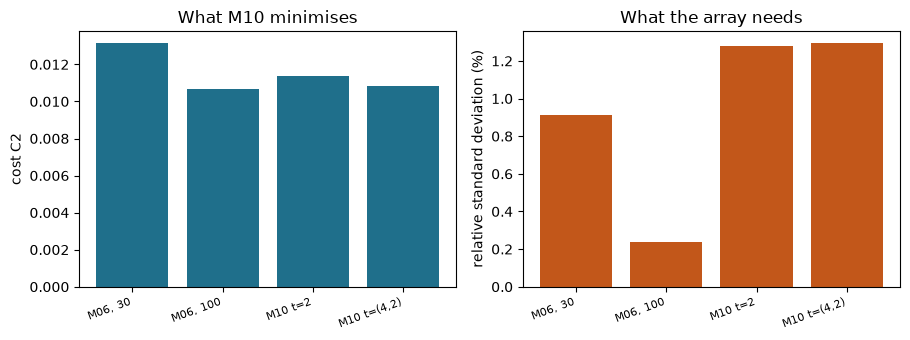

In [7]:
# cost C2 and relative standard deviation of the four phases: M06 at 30 and 100 iterations, the refinement
# and the powered refinement
runs = {"M06, 30": start, "M06, 100": long06, "M10 t=2": refined, "M10 t=(4,2)": powered}
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5))
a.bar(range(4), [cost.value_grad(r.phi)[0] for r in runs.values()], color="#1f6f8b")
b.bar(range(4), [r.history[-1]["rel_std"] for r in runs.values()], color="#c2571a")
for ax, label in ((a, "cost C2"), (b, "relative standard deviation (%)")):
    ax.set_xticks(range(4))
    ax.set_xticklabels(list(runs), rotation=20, ha="right", fontsize=8)
    ax.set_ylabel(label)
a.set_title("What M10 minimises")
b.set_title("What the array needs")
plt.tight_layout()
plt.show()

The two panels disagree about what is better, which is the lesson of the refinement. On the left the M10 phases have the lowest costs of the 30-iteration family (0.0114 and 0.0108 against 0.0131), and the 100-iteration weighted loop, which never saw the cost, is at 0.0107. On the right the ordering is reversed for the spread: the refinements are at 1.28 and 1.29 percent, above the starting 0.92 and far above the 0.24 of M06 at 100 iterations. The cost is a faithful statement of the efficiency target and a poor proxy for the spread. The figure does not show what the cost would be with a target efficiency closer to what the loop reaches, which the dial below explores.

### Asking for an efficiency

A projection loop has no efficiency parameter: the light that reaches the traps is whatever the loop's fixed point allows. The cost has one, $\eta$, and the `efficiency` argument of M10 sets it. The cell asks for 0.5 and for 0.7 of the input power, with 150 iterations each, and prints what the method delivers.

In [8]:
# the same cost with another efficiency target: the method is asked for 0.5 and for 0.7 of the input power
dial = {}
for want in (0.5, 0.7):
    dial[want] = m10_cg.run(setup, target, budget=Budget(150), rng=Rng(1), efficiency=want).history[-1]
    print(f"target {want}: efficiency {dial[want]['efficiency']:.4f}  "
          f"rel. std {dial[want]['rel_std']:.2e} %")

target 0.5: efficiency 0.5000  rel. std 4.26e-14 %
target 0.7: efficiency 0.7000  rel. std 1.35e-10 %


The figure puts every run of the notebook in one plane, with the efficiency on the horizontal axis and the relative standard deviation, on a log scale, on the vertical one.

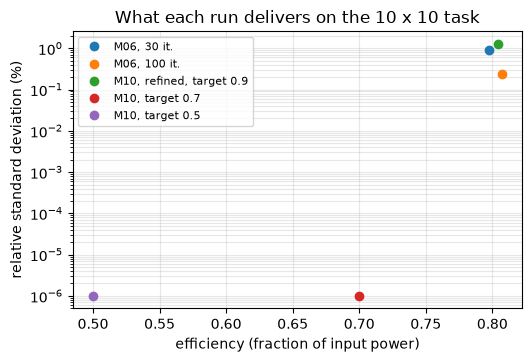

In [9]:
# every run in the plane of efficiency and relative standard deviation (floor of 1e-6 % for the plot)
points = {"M06, 30 it.": start.history[-1], "M06, 100 it.": long06.history[-1],
          "M10, refined, target 0.9": refined.history[-1],
          "M10, target 0.7": dial[0.7], "M10, target 0.5": dial[0.5]}
fig, ax = plt.subplots(figsize=(5.8, 3.6))
for label, h in points.items():
    ax.semilogy(h["efficiency"], max(h["rel_std"], 1e-6), "o", label=label)
ax.set_xlabel("efficiency (fraction of input power)")
ax.set_ylabel("relative standard deviation (%)")
ax.set_title("What each run delivers on the 10 x 10 task")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()

Both dial runs sit on their requested efficiency to four digits and have a relative standard deviation so small (4e-14 and 1e-10 percent) that it is plotted at the floor of the axis: when the requested efficiency is below what the physics allows, the cost has a zero, and CG finds a perfectly uniform array there. The three other runs (M06 twice, and M10 at its default target of 0.9) land in a band at 0.77 to 0.81 efficiency and 0.2 to 2 percent spread; none of them gets near 0.9, so the cost of the 0.9 target cannot be zero. The figure does not tell you the best value of $\eta$ for an experiment, nor that the points between 0.7 and 0.8 are reachable at zero spread; the whole curve between the two ends is the subject of the notebook `05-optimization/05-the-efficiency-uniformity-front`.

## Results

**Answer:** Minimising an explicit cost buys control and costs iterations. Refining the 30-iteration M06 phase with M10 lowers the cost from 0.0131 to 0.0114 and raises the relative standard deviation from 0.92 to 1.28 percent, because the cost also asks for the efficiency; the powered stages $t = (4, 2)$ lower the cost further, to 0.0108, and bring the weakest trap from 0.959 to 0.964 of the mean. Asked for 0.5 and 0.7 of the input power, M10 returns 0.5000 and 0.7000 with a relative standard deviation of 4.26e-14 and 1.35e-10 percent, which no projection loop can be asked for. The classical loop is still ahead at equal effort: M06 with 100 iterations has a cost of 0.0107, an efficiency of 0.8070 and a spread of 0.24 percent, lower than any M10 result of the notebook.

What the notebook does not show is a comparison with an independent implementation of the conjugate-gradient method, which does not exist among the dependencies, or the shaped targets where the powered cost was designed to matter.

## Summary

- Refining a weighted-GS hologram with M10 lowers the cost and raises the spread, because the cost also asks for the efficiency.
- The powered cost changes the weakest and the strongest trap, as the numbers above show, without changing the efficiency target.
- Asked for 0.5 and 0.7 of the input power, M10 returns exactly that with a perfectly equal array; weighted GS cannot be asked.
- Against the classical loop M10 is slower to a uniform array and the only one that takes an efficiency as an argument.
- No pinned reference implementation of M10 exists among the dependencies.

## References

- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539